In [1]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import ast
from adjustText import adjust_text


dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\USER\anaconda3\envs\python_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = df[df['job_title_short'] == 'Data Engineer']

In [3]:
df_exploded = df.explode('job_skills')

df_exploded

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,python,"{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,sql,"{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,c#,"{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,azure,"{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,airflow,"{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,spark,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,hadoop,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,kafka,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,kubernetes,"{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."


In [4]:
df_exploded.groupby('job_skills').agg(
    skill_count=('job_skills', 'count'),
    median_salary=('salary_year_avg', 'median')
)

,skill_count,median_salary
job_skills,,
airflow,25505,137280.0
airtable,68,92500.0
alteryx,2294,115000.0
angular,1446,140500.0
angular.js,45,116600.0
...,...,...
wrike,6,NaN
wsl,16,NaN
xamarin,10,121250.0


In [5]:
skill_stats = df_exploded.groupby('job_skills').agg(
    skill_count=('job_skills', 'count'),
    median_salary=('salary_year_avg', 'median')
)

skill_stats.sort_values(by='skill_count', ascending=False).head(10)

,skill_count,median_salary
job_skills,,
sql,113130,125000.0
python,108022,125000.0
aws,62049,130000.0
azure,60674,125000.0
spark,53656,134775.0
java,35559,134241.0
kafka,29073,140000.0
hadoop,28815,134241.0
scala,28716,137500.0


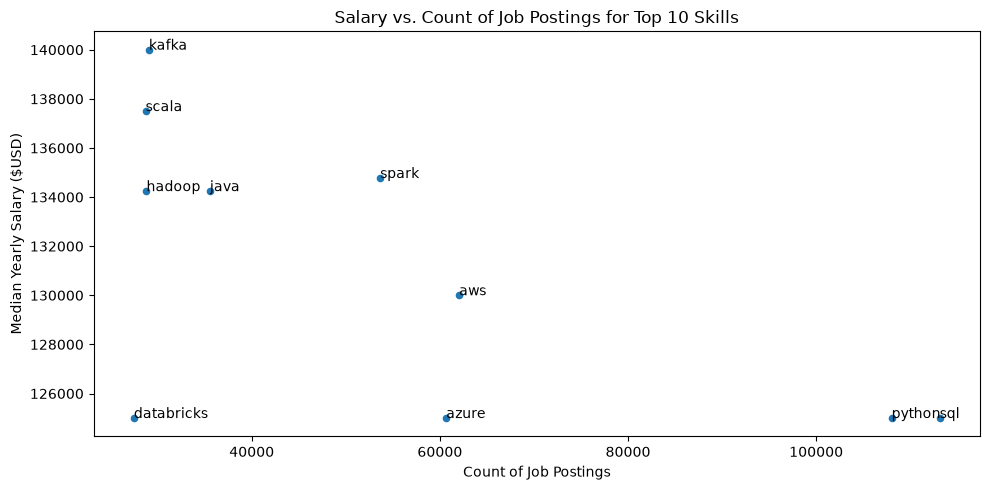

In [6]:
skills_stats = skill_stats.sort_values(by='skill_count', ascending=False).head(10)

skills_stats.plot(kind='scatter', x='skill_count', y='median_salary', figsize=(10, 5))
plt.xlabel('Count of Job Postings')
plt.ylabel('Median Yearly Salary ($USD)')
plt.title('Salary vs. Count of Job Postings for Top 10 Skills')
plt.tight_layout()



for i, txt in enumerate(skills_stats.index):
    plt.text(skills_stats['skill_count'].iloc[i], skills_stats['median_salary'].iloc[i], txt)

plt.show()


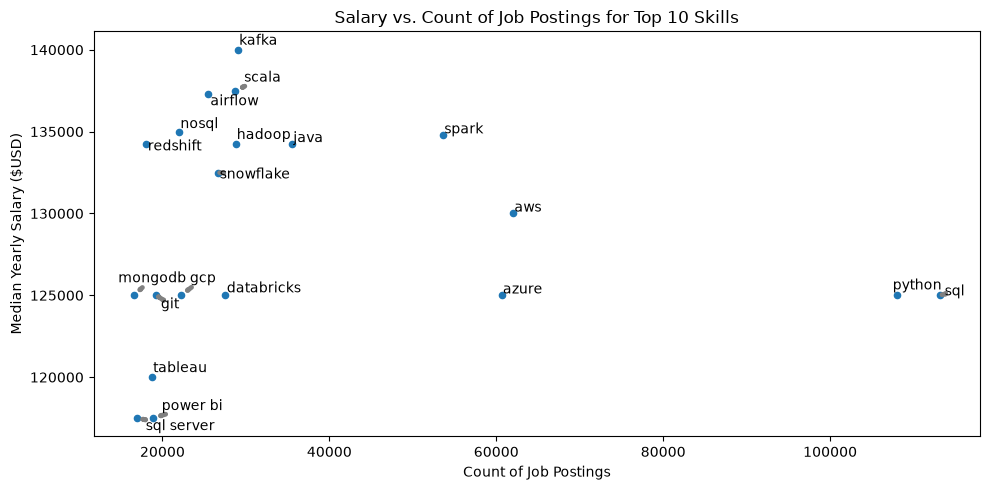

In [7]:
skills_stats = skill_stats.sort_values(by='skill_count', ascending=False).head(20)

skills_stats.plot(kind='scatter', x='skill_count', y='median_salary', figsize=(10, 5))
plt.xlabel('Count of Job Postings')
plt.ylabel('Median Yearly Salary ($USD)')
plt.title('Salary vs. Count of Job Postings for Top 10 Skills')
plt.tight_layout()

texts = []
for i, txt in enumerate(skills_stats.index):
    texts.append(plt.text(skills_stats['skill_count'].iloc[i], skills_stats['median_salary'].iloc[i], txt))

adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray', lw=3.5))

plt.show()


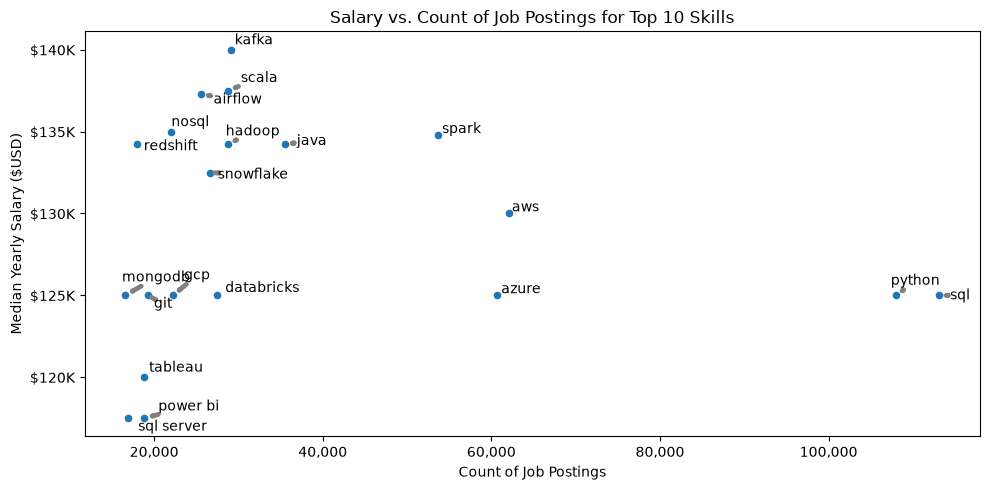

In [8]:
# fig, ax = plt.subplots()

skills_stats = skill_stats.sort_values(by='skill_count', ascending=False).head(20)

skills_stats.plot(kind='scatter', x='skill_count', y='median_salary', figsize=(10, 5))

texts = []
for i, txt in enumerate(skills_stats.index):
    texts.append(plt.text(skills_stats['skill_count'].iloc[i], skills_stats['median_salary'].iloc[i], txt))

adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray', lw=3.5))

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f'{int(x):,}')
)

plt.xlabel('Count of Job Postings')
plt.ylabel('Median Yearly Salary ($USD)')
plt.title('Salary vs. Count of Job Postings for Top 10 Skills')
plt.tight_layout()



plt.show()


In [9]:
df_technology = df['job_type_skills'].copy()

# Remove duplicates
df_technology = df_technology.drop_duplicates()

# Remove NaN values
df_technology = df_technology.dropna()

# Combine all dictionaries into one
technology_dict = {}

for row in df_technology:
    row_dict = ast.literal_eval(row)

    for key, value in row_dict.items():
        if key in technology_dict:
            technology_dict[key] += value
        else:
            technology_dict[key] = value

# Remove duplicates by converting values to set, then back to list
for key, value in technology_dict.items():
    technology_dict[key] = list(set(value))

technology_dict

{'analyst_tools': ['power bi',
  'sheets',
  'nuix',
  'outlook',
  'powerbi',
  'sharepoint',
  'word',
  'ssrs',
  'splunk',
  'visio',
  'sap',
  'datarobot',
  'spreadsheet',
  'tableau',
  'ms access',
  'powerpoint',
  'qlik',
  'cognos',
  'microstrategy',
  'excel',
  'alteryx',
  'spss',
  'ssis',
  'dax',
  'sas',
  'looker'],
 'cloud': ['databricks',
  'heroku',
  'aws',
  'colocation',
  'firebase',
  'linode',
  'bigquery',
  'digitalocean',
  'gcp',
  'vmware',
  'oracle',
  'ovh',
  'ibm cloud',
  'aurora',
  'snowflake',
  'openstack',
  'redshift',
  'azure',
  'watson'],
 'libraries': ['airflow',
  'rshiny',
  'dplyr',
  'nltk',
  'pyspark',
  'dlib',
  'selenium',
  'flutter',
  'pytorch',
  'numpy',
  'hadoop',
  'seaborn',
  'hugging face',
  'mxnet',
  'qt',
  'mlr',
  'gdpr',
  'theano',
  'tidyverse',
  'graphql',
  'jupyter',
  'tensorflow',
  'pandas',
  'spark',
  'scikit-learn',
  'keras',
  'plotly',
  'chainer',
  'mlpack',
  'opencv',
  'cordova',
  'elec

In [10]:
pd.DataFrame(list(technology_dict.items()), columns=['technology', 'skills'])

,technology,skills
0,analyst_tools,"[power bi, sheets, nuix, outlook, powerbi, sha..."
1,cloud,"[databricks, heroku, aws, colocation, firebase..."
2,libraries,"[airflow, rshiny, dplyr, nltk, pyspark, dlib, ..."
3,other,"[bitbucket, flow, docker, homebrew, codecommit..."
4,programming,"[vb.net, kotlin, perl, no-sql, sass, go, rust,..."
5,databases,"[postgresql, sql server, cassandra, dynamodb, ..."
6,webframeworks,"[blazor, ruby on rails, ember.js, flask, expre..."
7,os,"[windows, ubuntu, fedora, wsl, centos, linux, ..."
8,async,"[trello, clickup, smartsheet, monday.com, wrik..."
9,sync,"[webex, twilio, google chat, mattermost, zoom,..."


In [11]:
df_technology = pd.DataFrame(list(technology_dict.items()), columns=['technology', 'skills'])
df_technology = df_technology.explode('skills')

df_technology

,technology,skills
0,analyst_tools,power bi
0,analyst_tools,sheets
0,analyst_tools,nuix
0,analyst_tools,outlook
0,analyst_tools,powerbi
...,...,...
9,sync,wire
9,sync,unify
9,sync,slack
9,sync,symphony
